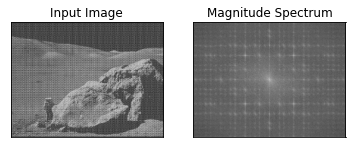

In [1]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt
 
img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)
 
dft = cv.dft(np.float32(img),flags = cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)
 
magnitude_spectrum = 20*np.log(cv.magnitude(dft_shift[:,:,0],dft_shift[:,:,1]))
 
plt.subplot(121),plt.imshow(img, cmap = 'gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(magnitude_spectrum, cmap = 'gray')
plt.title('Magnitude Spectrum'), plt.xticks([]), plt.yticks([])
plt.show()

In [2]:
#Filter creating
# Low pass filter
mask = np.zeros((img.shape[0],img.shape[1],2),np.uint8)
centerX, centerY = (int(img.shape[0] / 2),int(img.shape[1] / 2))
mask[centerX-50:centerX+50, centerY - 50:centerY+50,:] = 1

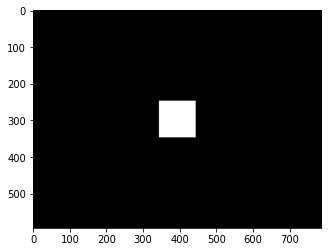

In [3]:
plt.imshow(mask[:,:,0], cmap = 'gray')

In [4]:
# Filtering
dft_shift = dft_shift*mask

C:\Users\Svetlana\AppData\Local\Temp\ipykernel_3864\3830399572.py:1: RuntimeWarning: divide by zero encountered in log
  filtering_magn_res = 20*np.log(cv.magnitude(dft_shift[:,:,0],dft_shift[:,:,1]))


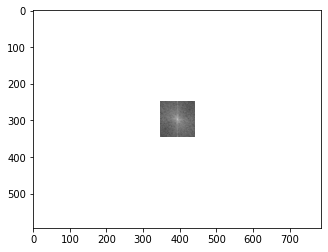

In [7]:
filtering_magn_res = 20*np.log(cv.magnitude(dft_shift[:,:,0],dft_shift[:,:,1]))
plt.imshow(filtering_magn_res, cmap='gray')

In [ ]:
#fshift = dft_shift*mask
f_ishift = np.fft.ifftshift(dft_shift)
img_back = cv.idft(f_ishift)
img_back = cv.magnitude(img_back[:,:,0],img_back[:,:,1])

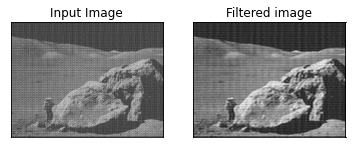

In [17]:
plt.subplot(121),plt.imshow(img, cmap = 'gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(img_back, cmap = 'gray')
plt.title('Filtered image'), plt.xticks([]), plt.yticks([])
plt.show()

In [ ]:
# Реализуйте высокочастотную фильтрацию на основе ядра Гаусса
# Реализуйте вычисление свертки с помощью преобразования Фурье
# Реализуйте удаление периодического шума с помощью преобразования Фурье

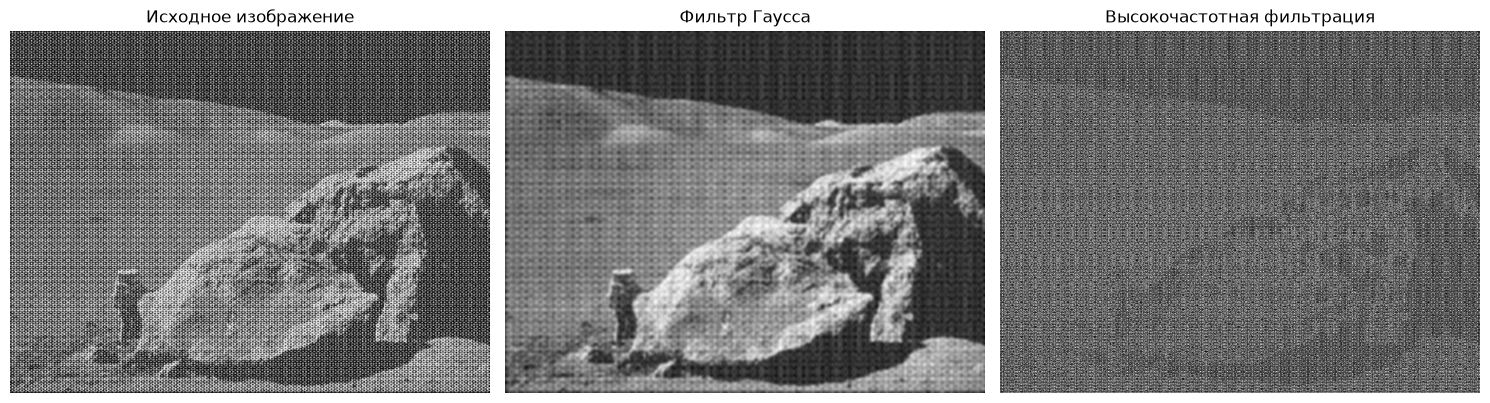

In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('periodic_noise.JPG', cv2.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError('Файл periodic_noise.JPG не найден')

gaussian = cv2.GaussianBlur(img, (9, 9), 2)

high_pass = img.astype(np.float32) - gaussian.astype(np.float32)

high_pass_abs = np.abs(high_pass)
max_value = np.percentile(high_pass_abs, 99)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(img, cmap='gray')
axes[0].set_title('Исходное изображение')

axes[1].imshow(gaussian, cmap='gray')
axes[1].set_title('Фильтр Гаусса')

axes[2].imshow(
    high_pass_abs,
    cmap='gray',
    vmin=0,
    vmax=max(max_value, 1)
)
axes[2].set_title('Высокочастотная фильтрация')

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()

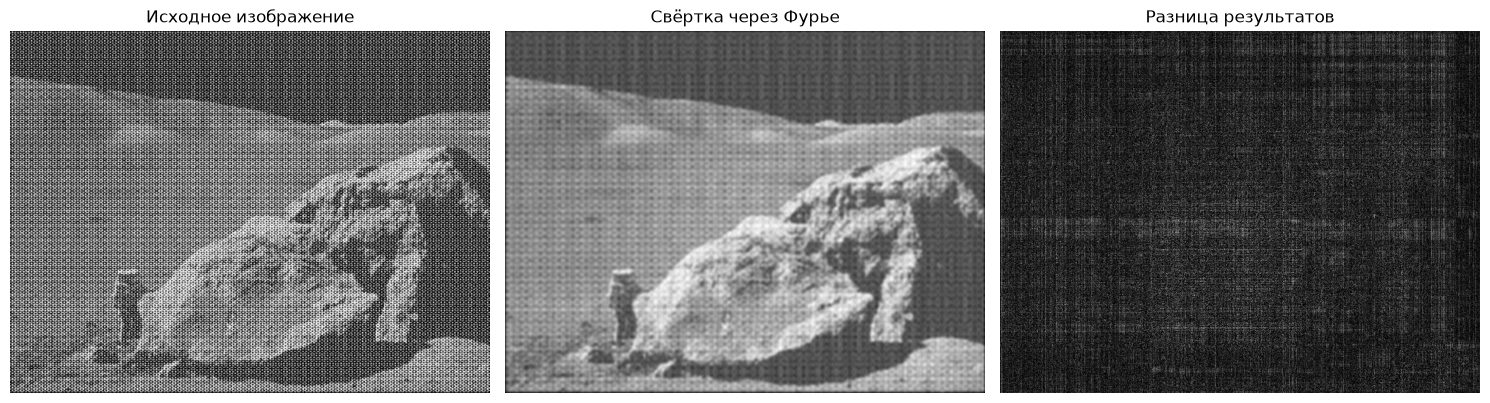

Максимальная разница: 2.2737367544323206e-13


In [7]:
kernel_1d = cv2.getGaussianKernel(9, 2)
kernel_2d = kernel_1d @ kernel_1d.T

spatial_result = cv2.filter2D(
    img.astype(np.float64), -1, kernel_2d,
    borderType=cv2.BORDER_CONSTANT
)

h, w = img.shape
kh, kw = kernel_2d.shape

shape = (h + kh - 1, w + kw - 1)

image_fft = np.fft.fft2(img.astype(np.float64), s=shape)
kernel_fft = np.fft.fft2(kernel_2d, s=shape)

result_fft = np.fft.ifft2(image_fft * kernel_fft).real

result_fft = result_fft[kh // 2:kh // 2 + h,
                        kw // 2:kw // 2 + w]

difference = np.abs(spatial_result - result_fft)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(img, cmap='gray')
axes[0].set_title('Исходное изображение')

axes[1].imshow(result_fft, cmap='gray')
axes[1].set_title('Свёртка через Фурье')

axes[2].imshow(difference, cmap='gray')
axes[2].set_title('Разница результатов')

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()

print('Максимальная разница:', np.max(difference))

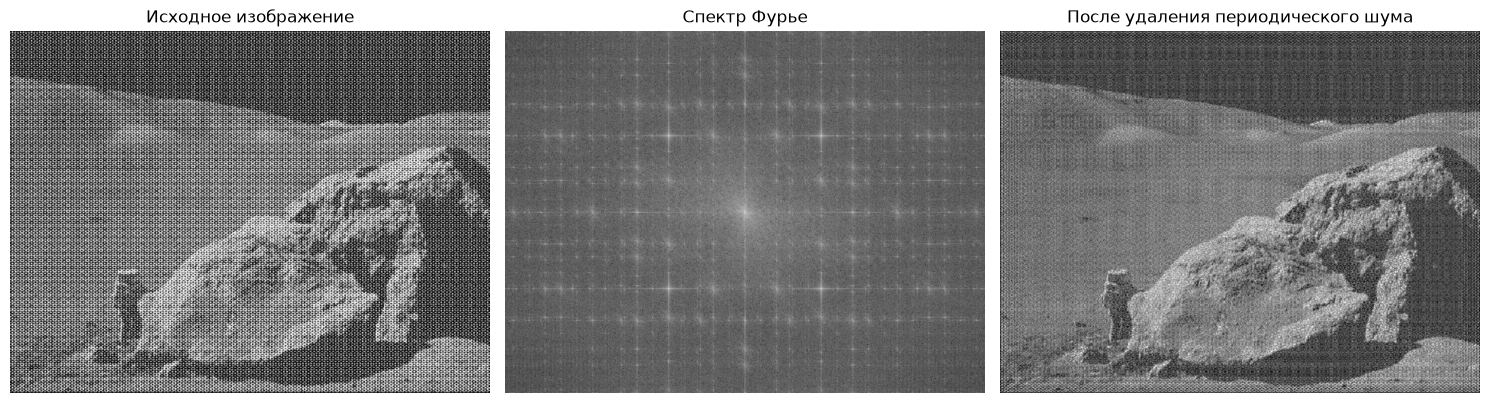

In [8]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

img = cv2.imread('periodic_noise.JPG', cv2.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError('Файл periodic_noise.JPG не найден')

f = np.fft.fft2(img.astype(np.float32))
fshift = np.fft.fftshift(f)

magnitude = np.log1p(np.abs(fshift))

rows, cols = img.shape
cy, cx = rows // 2, cols // 2

spectrum = cv2.GaussianBlur(
    magnitude.astype(np.float32), (3, 3), 0
)

spectrum[cy-20:cy+21, cx-20:cx+21] = 0

local_max = cv2.dilate(spectrum, np.ones((9, 9), np.uint8))

threshold = np.percentile(spectrum, 99.9)

peaks = (spectrum == local_max) & (spectrum > threshold)

mask = np.ones((rows, cols), dtype=np.float32)

ys, xs = np.where(peaks)

for y, x in zip(ys, xs):
    for py, px in [(y, x), (2*cy-y, 2*cx-x)]:
        if 0 <= py < rows and 0 <= px < cols:
            cv2.circle(mask, (int(px), int(py)), 4, 0, -1)

filtered_fft = fshift * mask

filtered = np.fft.ifft2(
    np.fft.ifftshift(filtered_fft)
).real

filtered = np.clip(filtered, 0, 255).astype(np.uint8)


fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(img, cmap='gray')
axes[0].set_title('Исходное изображение')

axes[1].imshow(np.log1p(np.abs(fshift)), cmap='gray')
axes[1].set_title('Спектр Фурье')

axes[2].imshow(filtered, cmap='gray')
axes[2].set_title('После удаления периодического шума')

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()